# Earthquakes in 2026: A Guided Tour

*What the planet has been up to this year — explained for non-experts, using live
data from the U.S. Geological Survey.*

This notebook analyzes every earthquake of **magnitude 2.5 or greater** recorded
worldwide by the [USGS](https://earthquake.usgs.gov/) from **January 1 through
July 8, 2026** — 14,134 earthquakes in all. The data comes from this repository's
sync pipeline (see `README.md`), snapshotted to `data/earthquakes_2026.csv` so the
analysis is fully reproducible without credentials or network access.

**The short version, if you read nothing else:**

1. **2026 is a textbook-average year so far.** Through July 8 the planet produced
   8 quakes of magnitude 7+ and 76 of magnitude 6+ — almost exactly the long-term
   average pace. The Earth is not "acting up," even when headlines suggest otherwise.
2. **The scariest event was a rare "doublet" in Venezuela** on June 24: a magnitude
   7.2 followed **37 seconds later** by a 7.5 on the same fault system, both shallow
   and close to towns — the year's only red-alert events.
3. **The biggest quake (M7.8, Philippines, June 7) was not the most dangerous**, and
   a modest M4.6 in California generated more "I felt it!" reports than every
   magnitude-7 event combined. Where a quake happens matters more than how big it is.
4. **Japan's 2011 tsunami zone has been restless**, with an M7.4 in April and a
   drumbeat of M6+ quakes offshore of Tōhoku — a reminder that great earthquakes
   echo for decades.
5. **June was the wild month**: 20 quakes of M6+ (vs. ~12 in a typical month) and
   4 of the year's 5 highest-alert events within 18 days — a good lesson in how
   randomness clusters.

*A note on numbers: the prose refers to the July 9, 2026 snapshot. If you refresh
the data (see the last section), the code recomputes but the narrative won't.*

## 1. The data

Each row in the catalog is one seismic event located by the USGS National
Earthquake Information Center and its partner networks. The columns we'll lean on:

| Column | Meaning |
| --- | --- |
| `magnitude` | Size of the earthquake (more on this scale below) |
| `depth_km` | How far below the surface the rupture started |
| `latitude`, `longitude`, `place` | Where it happened |
| `event_time` | When it happened (UTC) |
| `felt` | Number of people who filed a ["Did You Feel It?"](https://earthquake.usgs.gov/data/dyfi/) report |
| `alert` | [PAGER](https://earthquake.usgs.gov/data/pager/) humanitarian-impact alert: green / yellow / orange / red |
| `tsunami` | 1 if the event triggered a tsunami message |
| `event_type` | Almost all are `earthquake`; a few are mining blasts, which we drop |

One important filter up front: the catalog includes a small number of human-caused
bangs — mining and quarry blasts big enough to register on seismometers. They're
interesting, but they're not tectonics, so we set them aside.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Chart styling: a small, colorblind-safe palette used throughout.
COL = {
    "blue": "#2a78d6", "blue_light": "#86b6ef", "blue_dark": "#0d366b",
    "red": "#e34948", "ink": "#0b0b0b", "ink2": "#52514e",
    "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7",
    "surface": "#fcfcfb",
}
plt.rcParams.update({
    "figure.facecolor": COL["surface"], "axes.facecolor": COL["surface"],
    "savefig.facecolor": COL["surface"],
    "axes.edgecolor": COL["axis"], "axes.labelcolor": COL["ink2"],
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True,
    "xtick.color": COL["muted"], "ytick.color": COL["muted"],
    "text.color": COL["ink"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "figure.dpi": 110, "legend.frameon": False,
})

df = pd.read_csv("data/earthquakes_2026.csv")
for c in ("event_time", "updated_time"):
    df[c] = pd.to_datetime(df[c], format="ISO8601", utc=True)

quakes = df[df["event_type"] == "earthquake"].copy()
print(f"{len(df):,} catalog records -> {len(quakes):,} earthquakes "
      f"({len(df) - len(quakes)} human-caused events removed)")
print(f"Coverage: {quakes['event_time'].min():%b %d, %Y %H:%M} UTC "
      f"to {quakes['event_time'].max():%b %d, %Y %H:%M} UTC")

14,222 catalog records -> 14,134 earthquakes (88 human-caused events removed)
Coverage: Jan 01, 2026 00:03 UTC to Jul 08, 2026 23:44 UTC


In [2]:
# A few example rows, most recent first.
(quakes[["event_time", "magnitude", "place", "depth_km", "felt", "alert", "tsunami"]]
 .sort_values("event_time", ascending=False)
 .head(5))

,event_time,magnitude,place,depth_km,felt,alert,tsunami
14221,2026-07-08 23:44:13.741000+00:00,5.0,"1 km NNW of Xunchang, China",10.000,1.0,NaN,0
14220,2026-07-08 23:27:05.890000+00:00,4.4,"154 km NE of Lucapa, Angola",10.000,NaN,NaN,0
14219,2026-07-08 21:23:43.522000+00:00,2.5,"58 km WNW of Anchor Point, Alaska",106.000,NaN,NaN,0
14218,2026-07-08 21:11:49.440000+00:00,3.9,"174 km SSE of Lárdos, Greece",31.054,NaN,NaN,0
14217,2026-07-08 20:32:04.403000+00:00,4.9,"69 km NE of Sulangan, Philippines",10.000,NaN,NaN,0


## 2. How to read earthquake numbers

Two things about the magnitude scale trip everyone up:

* **It's logarithmic.** Each whole step (M5 → M6) means the ground shakes about
  **10× harder** and the quake releases about **32× more energy**. Two steps
  (M5 → M7) is roughly **1,000× more energy**. So "a 7.8 and a couple of 6s" is
  not "roughly similar events" — the 7.8 dwarfs them.
* **Magnitude is not damage.** A magnitude tells you how much energy left the
  fault, not what happened to people. Depth, distance to towns, soil conditions,
  and building quality decide the human toll. We'll see dramatic examples below.

A rough field guide:

| Magnitude | What it's like |
| --- | --- |
| 2.5–3.9 | Recorded by instruments; felt only if it's shallow and you're close |
| 4.0–4.9 | Rattles windows and nerves near the epicenter; damage rare |
| 5.0–5.9 | Can damage weak buildings close by |
| 6.0–6.9 | Destructive if shallow and near a city |
| 7.0–7.9 | Major earthquake; serious hazard over a wide area |
| 8.0+ | "Great" earthquake; regional catastrophe potential (none so far in 2026) |

In [3]:
def n_at_least(m):
    return int((quakes["magnitude"] >= m).sum())

biggest = quakes.loc[quakes["magnitude"].idxmax()]
# Energy scales as 10^(1.5 x magnitude)
energy_vs_smallest = 10 ** (1.5 * (biggest["magnitude"] - 2.5))

print("2026 headline numbers (Jan 1 - Jul 8)")
print("-" * 46)
print(f"  Earthquakes M2.5+              {len(quakes):>10,}")
print(f"  ... of which M5+ (damaging?)   {n_at_least(5.0):>10,}")
print(f"  ... of which M6+ (strong)      {n_at_least(6.0):>10,}")
print(f"  ... of which M7+ (major)       {n_at_least(7.0):>10,}")
print(f"  ... of which M8+ (great)       {n_at_least(8.0):>10,}")
print(f"  Largest: M{biggest['magnitude']} — {biggest['place']}")
print(f"           ({biggest['event_time']:%B %d}, depth {biggest['depth_km']:.0f} km)")
print(f"  Energy of the largest vs. the smallest in this catalog: "
      f"~{energy_vs_smallest / 1e6:,.0f} million x")
print(f"  'Did You Feel It?' reports filed: {int(quakes['felt'].sum()):,}")
print(f"  Events that triggered a tsunami message: {int((quakes['tsunami'] == 1).sum())}")
print(f"  PAGER alerts — yellow: {(quakes['alert'] == 'yellow').sum()}, "
      f"orange: {(quakes['alert'] == 'orange').sum()}, "
      f"red: {(quakes['alert'] == 'red').sum()}")

2026 headline numbers (Jan 1 - Jul 8)
----------------------------------------------
  Earthquakes M2.5+                  14,134
  ... of which M5+ (damaging?)          961
  ... of which M6+ (strong)              76
  ... of which M7+ (major)                8
  ... of which M8+ (great)                0
  Largest: M7.8 — 25 km SW of Kablalan, Philippines
           (June 07, depth 57 km)
  Energy of the largest vs. the smallest in this catalog: ~89 million x
  'Did You Feel It?' reports filed: 154,121
  Events that triggered a tsunami message: 34
  PAGER alerts — yellow: 9, orange: 3, red: 2


### One catalog, two lenses

Before we go further, one honest caveat — the single most useful thing to know
about *any* earthquake dataset. Seismometers don't cover the planet evenly. The
U.S. is blanketed with them, so the catalog picks up every M2.5 tremor in Alaska
or California. In the middle of the Pacific, a quake needs to reach roughly
**M4.5** before enough distant stations register it.

You can *see* this in the shape of the magnitude histogram below. Physics says
small quakes vastly outnumber big ones, so the bars should rise steadily as
magnitude falls. Instead there are two humps: a global hump that peaks around
M4.4 and falls off a cliff below it (smaller quakes elsewhere go undetected — the
catalog is only *complete* worldwide above ~M4.5), and a U.S. hump at the far
left, where dense local networks catch the small stuff.

So: **counts of small quakes tell you where the sensors are; counts of big quakes
tell you about the planet.** We'll use M4.5+ (or higher) whenever we make global
claims.

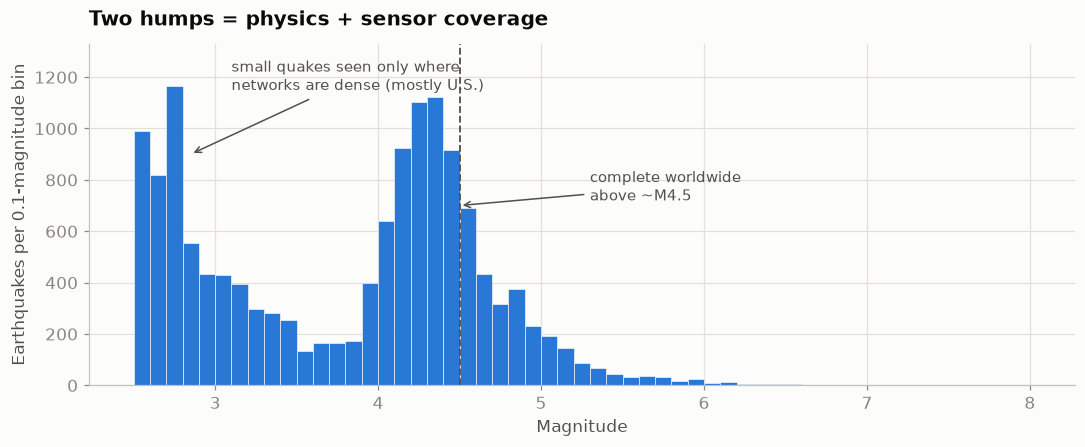

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.arange(2.5, 8.01, 0.1)
ax.hist(quakes["magnitude"], bins=bins, color=COL["blue"], edgecolor=COL["surface"],
        linewidth=0.4)
ax.axvline(4.5, color=COL["ink2"], linestyle="--", linewidth=1.2)
ax.set_ylim(0, 1330)
ax.annotate("complete worldwide\nabove ~M4.5", xy=(4.5, 700), xytext=(5.3, 720),
            fontsize=10, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.annotate("small quakes seen only where\nnetworks are dense (mostly U.S.)",
            xy=(2.85, 900), xytext=(3.1, 1150), fontsize=10, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.set_title("Two humps = physics + sensor coverage")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Earthquakes per 0.1-magnitude bin")
plt.tight_layout()
plt.show()

## 3. The year at a glance

How busy has 2026 been, day by day? Below, each dot is one day's count of recorded
quakes; the line smooths it to a 7-day average. The three biggest news events of
the year are marked — you can see each one kick up a plume of aftershocks.

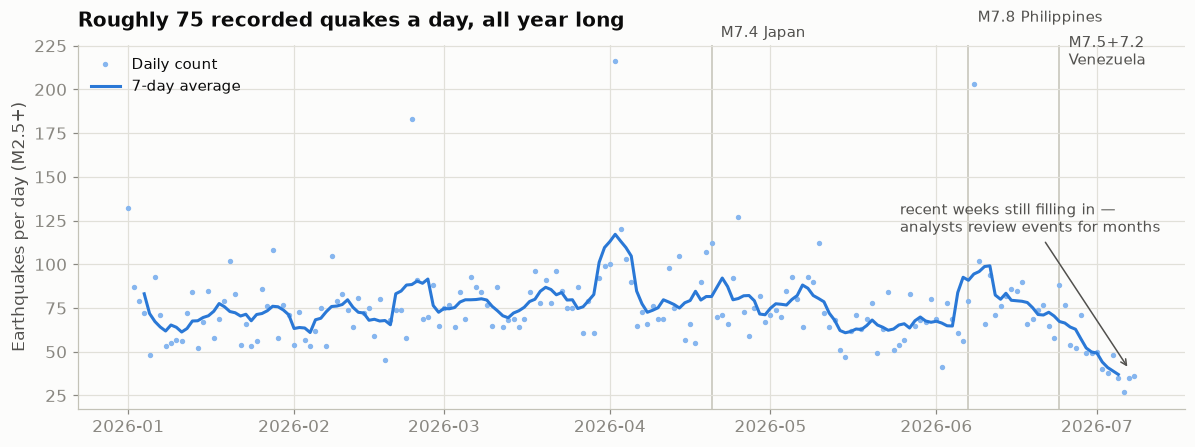

In [5]:
daily = quakes.set_index("event_time").resample("D").size()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(daily.index, daily.values, ".", color=COL["blue_light"], markersize=5,
        label="Daily count")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=COL["blue"],
        linewidth=2, label="7-day average")

for date, label, dy in [("2026-04-20", "M7.4 Japan", 16),
                        ("2026-06-07", "M7.8 Philippines", 26),
                        ("2026-06-24", "M7.5+7.2\nVenezuela", -2)]:
    d = pd.Timestamp(date, tz="UTC")
    ax.axvline(d, color=COL["axis"], linewidth=1, zorder=0)
    ax.annotate(label, xy=(d, daily.max()), xytext=(6, dy),
                textcoords="offset points", fontsize=9.5, color=COL["ink2"])

ax.annotate("recent weeks still filling in —\nanalysts review events for months",
            xy=(daily.index[-2], 40), xytext=(-150, 90), textcoords="offset points",
            fontsize=9.5, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.set_title("Roughly 75 recorded quakes a day, all year long")
ax.set_ylabel("Earthquakes per day (M2.5+)")
ax.legend(loc="upper left", fontsize=9.5)
plt.tight_layout()
plt.show()

The background rate is remarkably steady — the planet doesn't take days off. (The
apparent slump in the final two weeks is bookkeeping, not geology: seismic
analysts keep adding and revising smaller events for weeks after they happen, so
the most recent days always look artificially quiet. One more catalog quirk worth
knowing.) What *does* vary is the arrival of **big** quakes, which is much closer
to a lottery.
Here's the monthly count of M6+ events against the long-term global average
(~150 per year, i.e. ~12.5 per month):

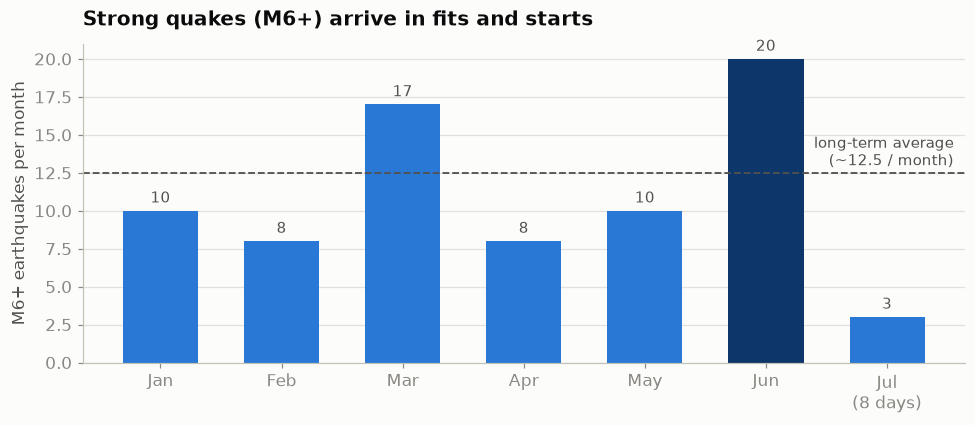

In [6]:
m6 = quakes[quakes["magnitude"] >= 6.0]
monthly_m6 = m6.set_index("event_time").resample("MS").size()

fig, ax = plt.subplots(figsize=(9, 4))
labels = [d.strftime("%b") for d in monthly_m6.index]
labels[-1] += "\n(8 days)"
colors = [COL["blue"]] * len(monthly_m6)
colors[5] = COL["blue_dark"]          # June, the outlier month
bars = ax.bar(labels, monthly_m6.values, color=colors, width=0.62)
ax.bar_label(bars, padding=3, fontsize=10, color=COL["ink2"])
ax.axhline(12.5, color=COL["ink2"], linestyle="--", linewidth=1.2)
ax.text(len(monthly_m6) - 0.45, 13.0, "long-term average\n(~12.5 / month)",
        fontsize=9.5, color=COL["ink2"], ha="right")
ax.set_title("Strong quakes (M6+) arrive in fits and starts")
ax.set_ylabel("M6+ earthquakes per month")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

June's 20 events look alarming next to April's 8 — but this is exactly what random
arrivals of rare events look like. Statisticians expect this much month-to-month
scatter even when nothing has changed about the underlying rate (for random
arrivals averaging 12.5/month, a 20-event month shows up every few years by luck
alone). Remember this chart the next time a busy news week makes it feel like
"earthquakes are increasing."

## 4. Where the Earth moves

Now plot every earthquake at its epicenter — no basemap needed, because six months
of seismicity *draws the map by itself*. The dots trace the boundaries of the
tectonic plates: the **Ring of Fire** around the Pacific, the mid-ocean ridges
snaking down the Atlantic and Indian Oceans, and the Alpine–Himalayan belt across
southern Europe and Asia.

Color shows **depth**. Shallow quakes (light blue) happen everywhere plates
interact. The deep ones (dark navy) happen almost exclusively where one plate
dives beneath another — a process called **subduction** — and mark the cold slab
sinking hundreds of kilometers into the mantle. That's why the deepest dots hug
the western Pacific trenches, Tonga–Fiji above all. The year's eight M7+ quakes
are starred in red.

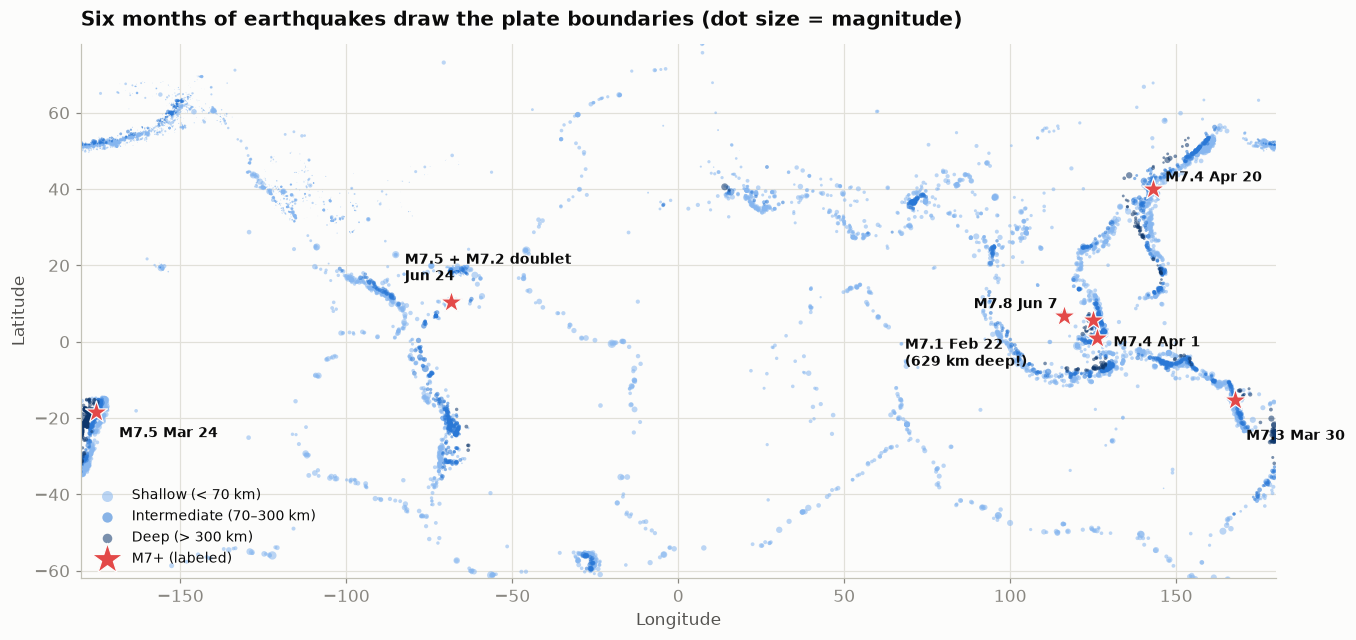

In [7]:
depth_bins = [(-15, 70, "Shallow (< 70 km)", COL["blue_light"]),
              (70, 300, "Intermediate (70–300 km)", COL["blue"]),
              (300, 800, "Deep (> 300 km)", COL["blue_dark"])]

fig, ax = plt.subplots(figsize=(12.5, 6.4))
for lo, hi, label, c in depth_bins:
    sel = quakes[(quakes["depth_km"] >= lo) & (quakes["depth_km"] < hi)]
    ax.scatter(sel["longitude"], sel["latitude"],
               s=(sel["magnitude"] - 2.2) ** 2.4 * 0.85,
               color=c, alpha=0.55, linewidths=0, label=label)

m7 = quakes[quakes["magnitude"] >= 7.0]
ax.scatter(m7["longitude"], m7["latitude"], s=230, marker="*",
           color=COL["red"], edgecolor=COL["surface"], linewidth=0.8,
           zorder=5, label="M7+ (labeled)")

m7_labels = [  # event_id -> (text, xytext offset)
    ("M7.1 Feb 22\n(629 km deep!)", 116.6, 6.5, -105, -32),
    ("M7.5 Mar 24", -174.0, -18.6, 12, -16),
    ("M7.3 Mar 30", 167.4, -15.3, 8, -26),
    ("M7.4 Apr 1", 126.5, 1.2, 10, -6),
    ("M7.4 Apr 20", 143.0, 39.6, 8, 6),
    ("M7.8 Jun 7", 124.9, 5.6, -78, 8),
    ("M7.5 + M7.2 doublet\nJun 24", -68.6, 10.5, -30, 14),
]
for text, x, y, dx, dy in m7_labels:
    ax.annotate(text, xy=(x, y), xytext=(dx, dy), textcoords="offset points",
                fontsize=9, color=COL["ink"], fontweight="bold")

ax.set_xlim(-180, 180)
ax.set_ylim(-62, 78)
ax.set_aspect(1.15)
ax.set_title("Six months of earthquakes draw the plate boundaries (dot size = magnitude)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower left", fontsize=9, markerscale=1.4, scatterpoints=1)
plt.tight_layout()
plt.show()

Two things worth noticing before we zoom in:

* **The dense speckle over Alaska and the western U.S.** is mostly the sensor
  effect from Section 2 — thousands of small quakes that only a dense network can
  see. Alaska alone contributes ~3,900 events, about 28% of the whole catalog.
* **Quiet is not safe.** Large regions with few dots (central U.S., northern
  Europe, Australia) really are less active — but plate interiors can still host
  rare, damaging quakes. Six months of data says little about thousand-year risks.

## 5. The big ones: 2026's magnitude-7+ club

Eight earthquakes reached magnitude 7 this year — right at the long-term average
pace of ~16 per year. Here they are:

In [8]:
m7_table = (m7.sort_values("event_time")
            [["event_time", "magnitude", "place", "depth_km", "alert", "tsunami", "felt"]]
            .copy())
m7_table["event_time"] = m7_table["event_time"].dt.strftime("%b %d %H:%M UTC")
m7_table.columns = ["When", "Mag", "Where", "Depth (km)", "PAGER alert",
                    "Tsunami msg", "Felt reports"]
m7_table.reset_index(drop=True)

,When,Mag,Where,Depth (km),PAGER alert,Tsunami msg,Felt reports
0,Feb 22 16:57 UTC,7.1,"57 km NNW of Kota Belud, Malaysia",629.000,green,1,59.0
1,Mar 24 04:37 UTC,7.5,"158 km W of Neiafu, Tonga",234.000,green,0,19.0
2,Mar 30 08:44 UTC,7.3,"51 km ENE of Luganville, Vanuatu",120.628,green,0,32.0
3,Apr 01 22:48 UTC,7.4,"129 km ESE of Bitung, Indonesia",35.000,green,0,59.0
4,Apr 20 07:52 UTC,7.4,"102 km ENE of Miyako, Japan",25.000,green,1,136.0
5,Jun 07 23:37 UTC,7.8,"25 km SW of Kablalan, Philippines",56.991,orange,0,382.0
6,Jun 24 22:04 UTC,7.2,"21 km ENE of San Felipe, Venezuela",27.588,red,0,NaN
7,Jun 24 22:05 UTC,7.5,"20 km ESE of Yumare, Venezuela",10.000,red,0,705.0


The stories behind the table:

* **Feb 22 — M7.1 under Borneo, Malaysia, 629 km deep.** The year's strangest
  quake. At that depth the rupture happened *inside a sinking slab of old Pacific
  seafloor*, farther below the surface than commercial jets fly above it. Deep
  quakes are felt over huge areas but are gentle at any one spot — this one
  drew 59 felt reports and zero damage. Depth is nature's shock absorber.
* **Mar 24 — M7.5 near Tonga (234 km deep)** and **Mar 30 — M7.3 in Vanuatu
  (121 km)**. The southwest Pacific's subduction zones doing what they always do;
  both too deep and too remote to cause harm. Tonga also hosted a swarm of
  M6s near Hihifo in March and April.
* **Apr 1 — M7.4 off Bitung, Indonesia (35 km).** A strong shallow quake in the
  Molucca Sea, mercifully offshore; a foretaste of the Philippines' June.
* **Apr 20 — M7.4 off Miyako, Japan (25 km).** The most-watched event of the
  spring: it struck the same offshore zone that produced the catastrophic 2011
  M9.1 Tōhoku earthquake, and it triggered tsunami messages (only small waves
  arrived). This area has been restless all year — see below.
* **Jun 7 — M7.8 near Kablalan, Mindanao, Philippines (57 km).** The year's
  largest quake, an orange alert. Three aftershocks of M6+ within 80 minutes and
  ~50 of M5+ since. Serious shaking across southern Mindanao — and a textbook
  aftershock sequence we'll dissect in the next section.
* **Jun 24 — the Venezuela doublet: M7.2, then M7.5 thirty-seven seconds later.**
  The year's most dangerous half-minute, and its only red alerts. More below.

### Same magnitude, different planet: why depth matters

The scatter below puts every M6+ quake on two axes — magnitude across, depth down
(note the log scale). The two red-alert Venezuela quakes sit in the shallow band
where humans live; the physically larger Tonga and Borneo events sit hundreds of
kilometers down, where they can't hurt anyone. **When you hear a magnitude on the
news, your second question should always be "how deep?"** (and your third, "near
whom?").

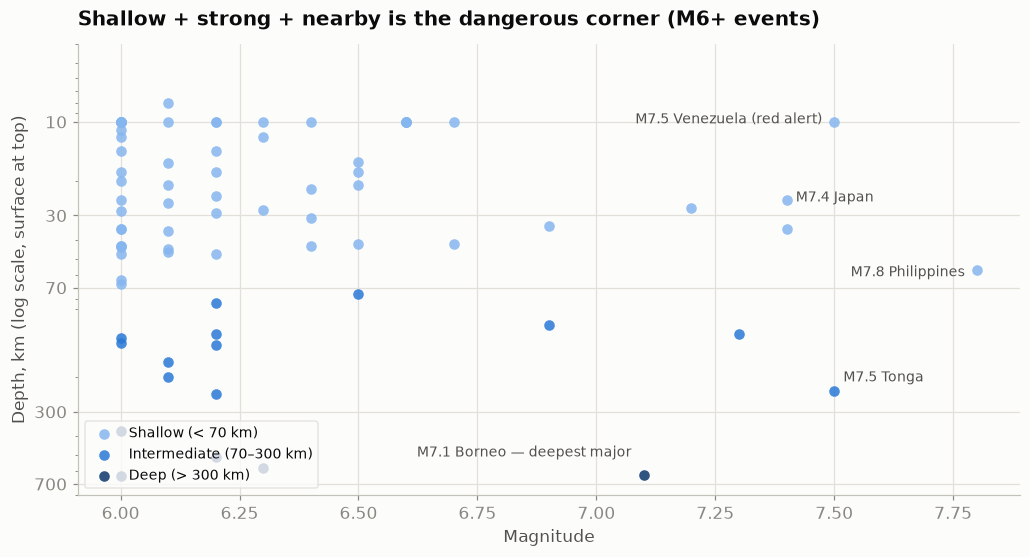

In [9]:
m6plus = quakes[quakes["magnitude"] >= 6.0].copy()
m6plus["depth_plot"] = m6plus["depth_km"].clip(lower=4)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for lo, hi, label, c in depth_bins:
    sel = m6plus[(m6plus["depth_km"] >= lo) & (m6plus["depth_km"] < hi)]
    ax.scatter(sel["magnitude"], sel["depth_plot"], s=48, color=c, alpha=0.85,
               linewidths=0, label=label)

for eid_place, dx, dy, ha in [("Yumare", -8, -1, "right"), ("Kablalan", -8, -4, "right"),
                              ("Kota Belud", -8, 12, "right"), ("Neiafu", 6, 6, "left"),
                              ("Miyako", 6, -1, "left")]:
    row = m6plus[m6plus["place"].str.contains(eid_place, na=False)].iloc[0]
    short = {"Yumare": "M7.5 Venezuela (red alert)",
             "Kablalan": "M7.8 Philippines",
             "Kota Belud": "M7.1 Borneo — deepest major",
             "Neiafu": "M7.5 Tonga",
             "Miyako": "M7.4 Japan"}[eid_place]
    ax.annotate(short, xy=(row["magnitude"], row["depth_plot"]),
                xytext=(dx, dy), textcoords="offset points",
                fontsize=9, color=COL["ink2"], ha=ha)

ax.set_yscale("log")
ax.set_ylim(800, 4)
ax.set_yticks([10, 30, 70, 300, 700], labels=["10", "30", "70", "300", "700"])
ax.set_title("Shallow + strong + nearby is the dangerous corner (M6+ events)")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Depth, km (log scale, surface at top)")
ax.legend(loc="lower left", fontsize=9, frameon=True,
          facecolor=COL["surface"], edgecolor=COL["grid"])
plt.tight_layout()
plt.show()

### Japan: echoes of 2011

A thread running through 2026: the offshore-Tōhoku region (the source of the 2011
M9.1 and its tsunami) produced not just April's M7.4 but a steady series of
strong quakes — M6.5 near Yamada (Mar 26), M6.7 near Ōfunato (May 15), M6.9 near
Noda (Jun 24) and M6.0 (Jul 1). In our snapshot, a small box drawn around that
coastline contains **226 quakes, six of M6+** — with April alone contributing 88
as aftershocks of the M7.4.

This is normal, if sobering: a magnitude-9 rupture re-loads stress all along its
edges, and its aftershock sequence remains detectable for *decades*. Japan's
early-warning systems and engineering are built for exactly this reality.

## 6. Aftershocks: the Earth's slow exhale

Big earthquakes don't end when the shaking stops — they hand off stress to the
surrounding rock, which releases it as **aftershocks**: many at first, then fewer
and fewer, following a remarkably universal decay law (Omori's law, known since
1894). Below is the daily count of quakes within the rupture region of the June 7
M7.8 in Mindanao.

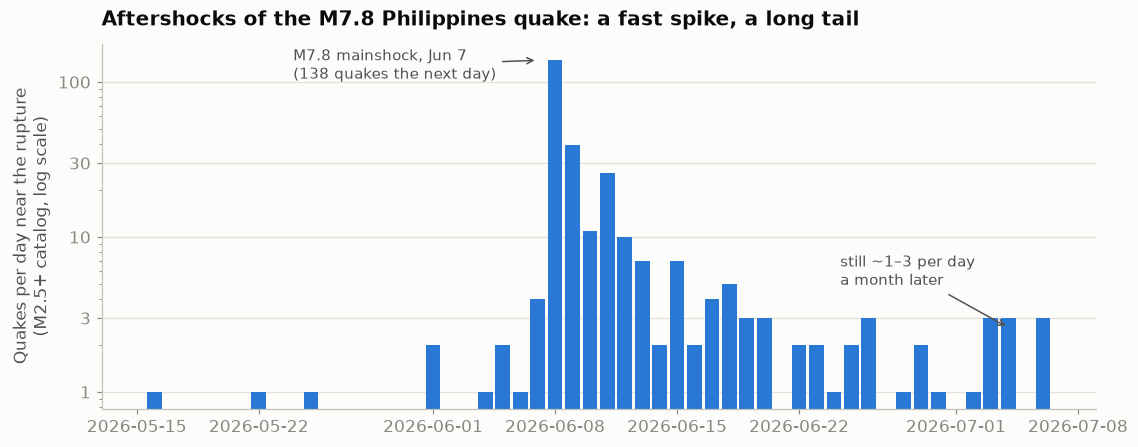

Aftershocks in this box since the mainshock: 284 (M5+: 47)
Quiet before: this same box logged just 9 quakes in the 3+ weeks before.


In [10]:
main = quakes[quakes["place"].str.contains("Kablalan", na=False)].iloc[0]
box = quakes[(quakes["latitude"].between(main["latitude"] - 1.5, main["latitude"] + 1.5))
             & (quakes["longitude"].between(main["longitude"] - 1.5, main["longitude"] + 1.5))
             & (quakes["event_time"] >= pd.Timestamp("2026-05-15", tz="UTC"))]
seq = box.set_index("event_time").resample("D").size()

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.bar(seq.index, seq.values, width=0.85, color=COL["blue"])
ax.set_yscale("log")
ax.set_yticks([1, 3, 10, 30, 100], labels=["1", "3", "10", "30", "100"])
main_day = main["event_time"].floor("D")
ax.annotate(f"M7.8 mainshock, Jun 7\n({int(seq.max())} quakes the next day)",
            xy=(main_day, seq.max()), xytext=(-160, -12), textcoords="offset points",
            fontsize=10, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.annotate("still ~1–3 per day\na month later", xy=(seq.index[-3], 2.6),
            xytext=(-110, 28), textcoords="offset points",
            fontsize=10, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.set_title("Aftershocks of the M7.8 Philippines quake: a fast spike, a long tail")
ax.set_ylabel("Quakes per day near the rupture\n(M2.5+ catalog, log scale)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

n_after = int(box[box["event_time"] > main["event_time"]].shape[0])
n_m5 = int((box[box["event_time"] > main["event_time"]]["magnitude"] >= 5).sum())
print(f"Aftershocks in this box since the mainshock: {n_after} (M5+: {n_m5})")
print("Quiet before: this same box logged just "
      f"{int((box['event_time'] < main['event_time']).sum())} quakes in the 3+ weeks before.")

Two practical lessons hide in this chart:

* **The first days are the risky ones.** Aftershock rates fall roughly with 1/time
  — day 2 has about half the quakes of day 1, day 10 about a tenth. That's why
  rescue crews fear the first 48 hours: buildings cracked by the mainshock meet
  the strongest aftershocks.
* **The catalog undersells aftershocks outside the U.S.** Remember the detection
  floor: near Mindanao, only aftershocks above ~M4 make this dataset. The true
  count, including small ones, is in the thousands. (This is also why the June 24
  Venezuela doublet shows "only" ~14 catalog aftershocks — the local small quakes
  are below the global network's threshold, not absent.)

## 7. Magnitude is not impact

The USGS runs a system called **PAGER** that estimates, within about half an hour,
how badly an earthquake is likely to have hurt people and economies. It issues a
color: **green** (little or no impact), **yellow** (localized), **orange**
(significant regional impact likely) or **red** (major disaster likely). PAGER
weighs *shaking + population + building fragility* — not magnitude alone.

2026's orange and red alerts make the point better than any lecture:

In [11]:
alerts = (quakes[quakes["alert"].isin(["orange", "red"])]
          .sort_values("event_time")
          [["event_time", "magnitude", "place", "depth_km", "mmi", "alert"]]
          .copy())
alerts["event_time"] = alerts["event_time"].dt.strftime("%b %d")
alerts.columns = ["When", "Mag", "Where", "Depth (km)",
                  "Peak shaking (MMI)", "PAGER"]
alerts.reset_index(drop=True)

,When,Mag,Where,Depth (km),Peak shaking (MMI),PAGER
0,May 18,5.1,"20 km NW of Liuzhou, China",10.000,6.714,orange
1,Jun 07,7.8,"25 km SW of Kablalan, Philippines",56.991,8.530,orange
2,Jun 16,6.3,"262 km SSE of Dunhuang, China",10.000,7.725,orange
3,Jun 24,7.2,"21 km ENE of San Felipe, Venezuela",27.588,8.566,red
4,Jun 24,7.5,"20 km ESE of Yumare, Venezuela",10.000,8.641,red


Look at the magnitude column: a **5.1** made the list (Liuzhou, China — shallow,
close to a city of millions) while dozens of M6+ quakes stayed green. The
Dunhuang M6.3 went orange for the same reason; meanwhile the M7.5 Tonga quake —
releasing roughly *4,000× more energy than Liuzhou* — rated green, because it
spent its fury 234 km underground, far from anyone.

The same lesson appears when we ask *who actually felt the shaking*. Every dot
below is one earthquake; height is the number of "Did You Feel It?" reports
submitted by the public.

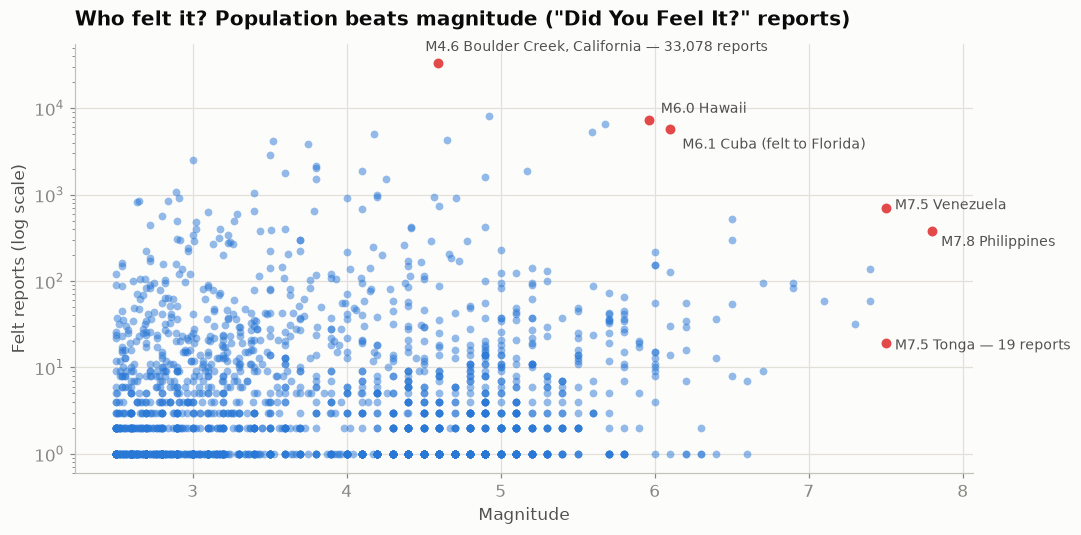

In [12]:
felt = quakes[quakes["felt"] > 0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(felt["magnitude"], felt["felt"], s=26, color=COL["blue"], alpha=0.5,
           linewidths=0)
ax.set_yscale("log")

for match, label, dx, dy in [
        ("Boulder Creek", "M4.6 Boulder Creek, California — 33,078 reports", -8, 8),
        ("Honaunau", "M6.0 Hawaii", 8, 5),
        ("Mantua, Cuba", "M6.1 Cuba (felt to Florida)", 8, -13),
        ("Yumare", "M7.5 Venezuela", 6, -1),
        ("Kablalan", "M7.8 Philippines", 6, -10),
        ("Neiafu", "M7.5 Tonga — 19 reports", 6, -4)]:
    row = felt[felt["place"].str.contains(match, na=False)].nlargest(1, "felt").iloc[0]
    ax.annotate(label, xy=(row["magnitude"], row["felt"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=COL["ink2"])
    ax.scatter([row["magnitude"]], [row["felt"]], s=42, color=COL["red"],
               zorder=5, linewidths=0)

ax.set_title('Who felt it? Population beats magnitude ("Did You Feel It?" reports)')
ax.set_xlabel("Magnitude")
ax.set_ylabel("Felt reports (log scale)")
plt.tight_layout()
plt.show()

A magnitude 4.6 under the Santa Cruz mountains out-reported every magnitude-7 on
Earth this year *combined* — because millions of people (with smartphones and a
habit of reporting) live on top of it. Conversely, the two most powerful quakes of
the year drew a few hundred reports each. Crowd-sourced shaking data measures
*people*, not just physics — which is exactly what makes it useful for rapid
impact assessment.

## 8. Close to home: the U.S. in 2026

No U.S. earthquake caused major damage this year, but several gave millions of
people a jolt:

* **Apr 2 — M4.6 Boulder Creek, CA**: the year's most-felt quake anywhere.
* **Jun 24 — M5.6 Redwood Valley, CA** (yellow alert) — Mendocino County's
  strongest shaking in years, the same day as the Venezuela doublet.
* **May 23 — M6.0 beneath the Big Island of Hawai'i** (yellow alert), ~23 km
  under the island's southern flank — part of the volcanic system's deep
  plumbing, and the largest U.S. quake of the year outside Alaska.
* **Apr 14 — M5.7 Silver Springs, NV** — a reminder that the Basin and Range is
  earthquake country too.
* **Jan 20 — M4.9 Indio, CA**, close to the southern San Andreas — scientifically
  interesting real estate, even at modest magnitude.
* **Mar 4 — M6.4 near Attu Station** at the far western tip of the Aleutians: the
  biggest U.S. quake of the year, centerpiece of a cluster that kept producing
  M5.5–5.8 events into May (plus an M6.1 in the Rat Islands on May 9).

In [13]:
top_felt = (quakes.nlargest(8, "felt")
            [["event_time", "magnitude", "place", "depth_km", "felt", "alert"]]
            .copy())
top_felt["event_time"] = top_felt["event_time"].dt.strftime("%b %d")
top_felt.columns = ["When", "Mag", "Where", "Depth (km)", "Felt reports", "PAGER"]
top_felt.reset_index(drop=True)

,When,Mag,Where,Depth (km),Felt reports,PAGER
0,Apr 02,4.590000,"1 km SE of Boulder Creek, CA",10.43,33078.0,green
1,Jan 20,4.922556,"20 km NNE of Indio, CA",3.09,8212.0,green
2,May 23,5.960000,"13 km S of Honaunau-Napoopoo, Hawaii",22.64,7208.0,yellow
3,Apr 14,5.680000,"20 km ESE of Silver Springs, Nevada",5.00,6515.0,green
4,Jun 08,6.100000,"104 km WNW of Mantua, Cuba",26.00,5776.0,green
5,Jun 24,5.590000,"11 km N of Redwood Valley, CA",8.85,5304.0,yellow
6,Feb 02,4.180000,"4 km SE of San Ramon, CA",9.56,5030.0,green
7,Jan 22,4.650000,"40 km S of Evanston, Wyoming",14.72,4304.0,green


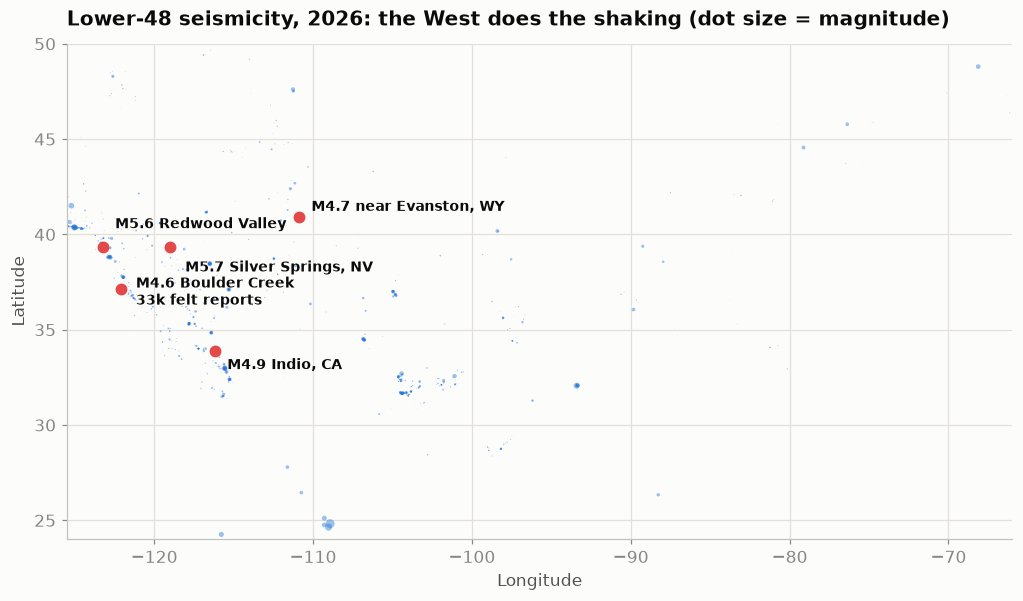

Where the U.S. dots are: California + Nevada line the plate boundary; the diffuse band through Utah/Wyoming is the Intermountain Seismic Belt; Texas and Oklahoma clusters are largely linked to oil & gas operations; Puerto Rico (off-map, ~940 events) is still settling after its 2020 sequence.


In [14]:
conus = quakes[(quakes["latitude"].between(24, 50))
               & (quakes["longitude"].between(-125.5, -66))]

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.scatter(conus["longitude"], conus["latitude"],
           s=(conus["magnitude"] - 2.2) ** 2.4 * 1.4,
           color=COL["blue"], alpha=0.45, linewidths=0)

highlights = [("Boulder Creek", "M4.6 Boulder Creek\n33k felt reports", 10, -10, "left"),
              ("Redwood Valley", "M5.6 Redwood Valley", 8, 12, "left"),
              ("Silver Springs", "M5.7 Silver Springs, NV", 10, -16, "left"),
              ("Indio", "M4.9 Indio, CA", 8, -12, "left"),
              ("Evanston", "M4.7 near Evanston, WY", 8, 4, "left")]
for match, label, dx, dy, ha in highlights:
    row = conus[conus["place"].str.contains(match, na=False)].nlargest(1, "felt").iloc[0]
    ax.scatter([row["longitude"]], [row["latitude"]], s=60, color=COL["red"],
               zorder=5, linewidths=0)
    ax.annotate(label, xy=(row["longitude"], row["latitude"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=COL["ink"],
                fontweight="bold", ha=ha, zorder=6)

ax.set_xlim(-125.5, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.2)
ax.set_title("Lower-48 seismicity, 2026: the West does the shaking (dot size = magnitude)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

print("Where the U.S. dots are: California + Nevada line the plate boundary; the "
      "diffuse band through Utah/Wyoming is the Intermountain Seismic Belt; "
      "Texas and Oklahoma clusters are largely linked to oil & gas operations; "
      "Puerto Rico (off-map, ~940 events) is still settling after its 2020 sequence.")

## 9. So… is 2026 unusual?

The question every seismologist gets at dinner parties. Let's answer it properly,
using only magnitudes where the catalog is globally complete, and comparing
against long-term global rates (USGS: roughly 1,300–1,700 M5+, ~135–155 M6+, and
~16 M7+ in a typical year):

In [15]:
days = (quakes["event_time"].max() - quakes["event_time"].min()).days + 1
frac = days / 365.25

observed = {"M5+": n_at_least(5.0), "M6+": n_at_least(6.0), "M7+": n_at_least(7.0)}
expected = {"M5+": f"{1300 * frac:,.0f} – {1700 * frac:,.0f}",
            "M6+": f"{135 * frac:,.0f} – {155 * frac:,.0f}",
            "M7+": f"{16 * frac:,.1f}"}
verdict = {"M5+": "upper end of normal", "M6+": "typical", "M7+": "typical"}

pd.DataFrame({"Observed (Jan 1 – Jul 8)": observed,
              f"Expected in {days} days": expected,
              "Verdict": verdict})

,Observed (Jan 1 – Jul 8),Expected in 189 days,Verdict
M5+,961,673 – 880,upper end of normal
M6+,76,70 – 80,typical
M7+,8,8.3,typical


Right on schedule — 8 major quakes when the average predicts ~8, and M6+ counts
inside the normal band. M5+ sits at the busy end, inflated by the vigorous
Philippine and Japanese aftershock sequences, which is how normal years work.

One more check, for the statistically curious: earthquake catalogs the world over
obey the **Gutenberg–Richter law** — each step down in magnitude brings roughly
10× more earthquakes (a straight line on a log plot, whose slope is called the
*b-value*, almost always ≈ 1). If 2026's catalog is healthy and the year is
normal, our data should fall on that line above the M4.5 completeness threshold:

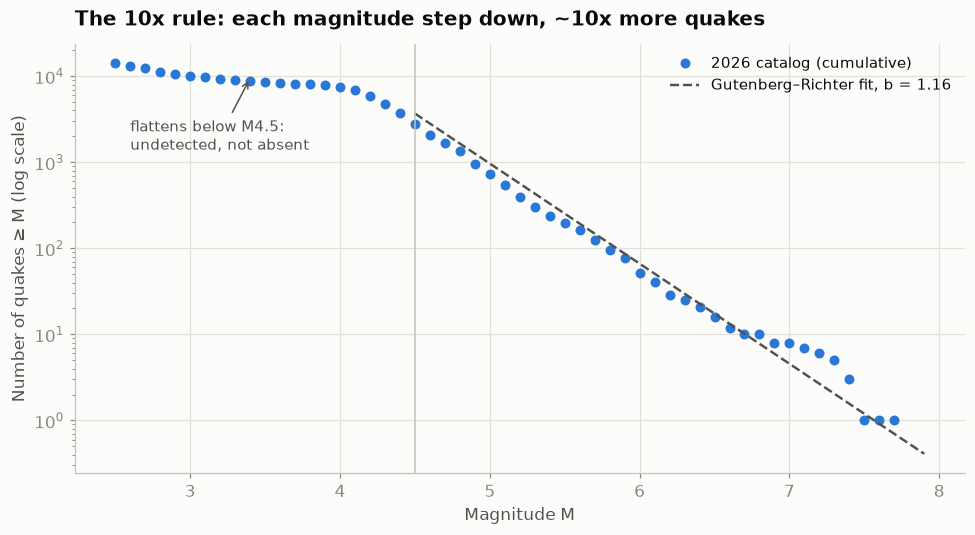

In [16]:
mags = np.arange(2.5, 8.0, 0.1)
counts = np.array([(quakes["magnitude"] >= m).sum() for m in mags])

# Fit b above the completeness threshold (maximum-likelihood, Aki 1965)
mc = 4.5
complete = quakes.loc[quakes["magnitude"] >= mc, "magnitude"]
b = np.log10(np.e) / (complete.mean() - (mc - 0.05))
a = np.log10(len(complete)) + b * mc
fit = 10 ** (a - b * mags)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mags, counts, "o", color=COL["blue"], markersize=5.5,
        label="2026 catalog (cumulative)")
keep = mags >= mc
ax.plot(mags[keep], fit[keep], "--", color=COL["ink2"], linewidth=1.6,
        label=f"Gutenberg–Richter fit, b = {b:.2f}")
ax.axvline(mc, color=COL["axis"], linewidth=1)
ax.annotate("flattens below M4.5:\nundetected, not absent", xy=(3.4, 9500),
            xytext=(2.6, 1400), fontsize=10, color=COL["ink2"],
            arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=1))
ax.set_yscale("log")
ax.set_title("The 10x rule: each magnitude step down, ~10x more quakes")
ax.set_xlabel("Magnitude M")
ax.set_ylabel("Number of quakes ≥ M (log scale)")
ax.legend(loc="upper right", fontsize=9.5)
plt.tight_layout()
plt.show()

The fitted b-value of ~1.2 is comfortably in the normal range (global values run
0.9–1.2 depending on period and catalog). Nothing about 2026's statistics is
anomalous — the drama was in *where* quakes landed, not *how many* there were.

## 10. Takeaways

1. **The planet's pulse is steady.** ~75 recorded quakes a day, M6+ and M7+
   arriving exactly on their long-term average pace. "Earthquakes are increasing"
   is a perception effect — better sensors, faster news, clustered luck.
2. **June 24's Venezuela doublet is the event to remember**: M7.2 + M7.5 within
   37 seconds, shallow, under populated coastline — the year's only red alerts.
   Doublets (two comparable mainshocks, one triggering the other) are rare and
   brutal: the second shock hits buildings the first already weakened.
3. **The biggest ≠ the worst.** The M7.8 Philippines quake, the year's largest,
   rated orange; a shallow M5.1 under a Chinese city also rated orange; and a
   deep M7.1 under Borneo hurt no one. Ask *how deep* and *near whom*, not just
   *how big*.
4. **Aftershocks follow the script**: Mindanao's sequence spiked and decayed just
   as Omori's 130-year-old law predicts, and Japan is still feeling 2011's echoes
   — including an M7.4 on the same fault zone this April.
5. **Crowd data has a human fingerprint**: a California M4.6 generated 33,000
   felt reports; a Tongan M7.5 got 19. Both facts are useful — one maps
   exposure, the other maps remoteness.
6. **Mind the catalog's blind spots.** Below ~M4.5, this dataset only sees quakes
   near dense networks (mostly the U.S.). Any "count" claim should state its
   magnitude floor — a good habit with *any* dataset, not just this one.

### Further reading

* [USGS Latest Earthquakes map](https://earthquake.usgs.gov/earthquakes/map/) — the live feed this data comes from
* [Did You Feel It?](https://earthquake.usgs.gov/data/dyfi/) — file a report next time you feel one
* [PAGER alerts](https://earthquake.usgs.gov/data/pager/) — how impact colors are assigned
* [Earthquake statistics & FAQ](https://www.usgs.gov/programs/earthquake-hazards/lists-maps-and-statistics) — the long-term averages used above

### Reproducibility

* **Data**: `data/earthquakes_2026.csv`, snapshotted July 9, 2026 by
  `snapshot_2026.py` (M2.5+, Jan 1 through the last complete UTC day, fetched from
  the USGS FDSN API with the same transform as the hourly Supabase sync).
* **Refresh**: run `python snapshot_2026.py` locally, or trigger the
  *Snapshot 2026 Data* GitHub Actions workflow, then re-run this notebook
  top-to-bottom. Charts and computed numbers update; prose refers to the July 9
  snapshot.
* USGS data are in the public domain. Analysis: pandas + matplotlib only.